In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("scikit-learn:", sklearn.__version__)

pandas      : 3.0.6
numpy       : 2.4.6
matplotlib  : 3.11.2
seaborn     : 0.13.2
scikit-learn: 1.9.1


In [ ]:
df = pd.read_csv("../data/train.csv")

In [3]:
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [5]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
df.isnull().sum().sort_values(ascending=False).head(10)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64

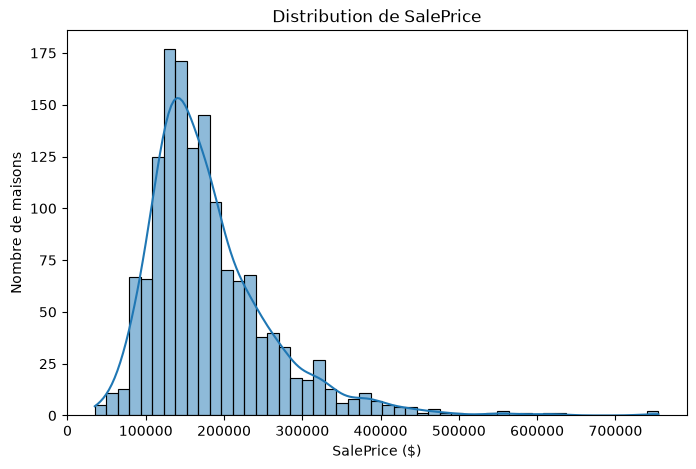

Skewness : 1.8828757597682129


In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution de SalePrice")
plt.xlabel("SalePrice ($)")
plt.ylabel("Nombre de maisons")
plt.show()

print("Skewness :", df["SalePrice"].skew())

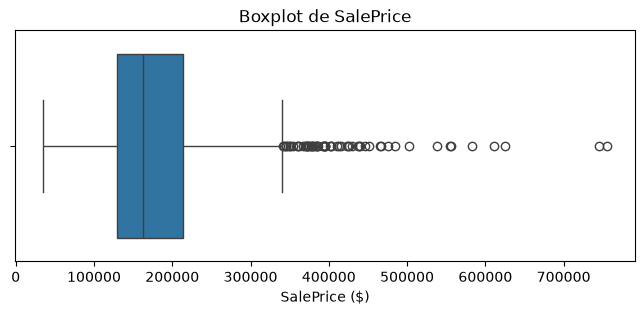

In [8]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["SalePrice"])
plt.title("Boxplot de SalePrice")
plt.xlabel("SalePrice ($)")
plt.show()

# outliers par la règle de l'IQR

In [13]:
Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)
IQR = Q3 - Q1
limite_haute = Q3 + 1.5 * IQR
print(f"Q1={Q1:.0f} | Q3={Q3:.0f} | IQR={IQR:.0f} | limite haute={limite_haute:.0f}")
print("Nombre d'outliers :", (df["SalePrice"] > limite_haute).sum())

Q1=129975 | Q3=214000 | IQR=84025 | limite haute=340038
Nombre d'outliers : 61


# transformation log de la cible

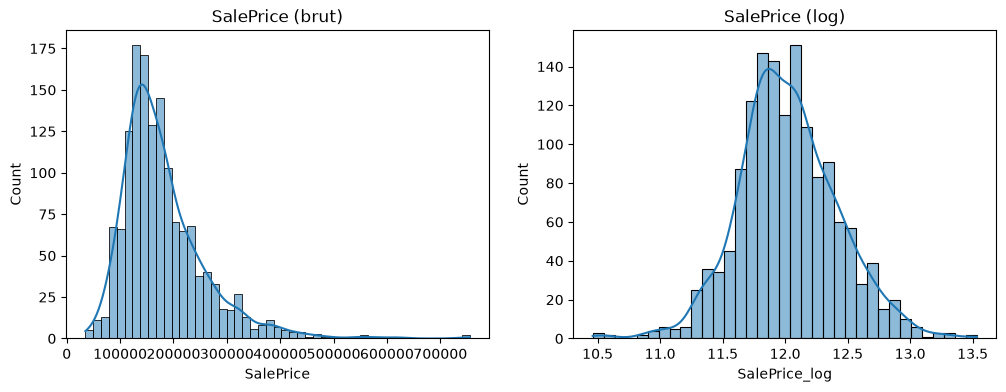

Skew brut : 1.8828757597682129
Skew log  : 0.12134661989685333


In [10]:
df["SalePrice_log"] = np.log1p(df["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0]);     axes[0].set_title("SalePrice (brut)")
sns.histplot(df["SalePrice_log"], kde=True, ax=axes[1]); axes[1].set_title("SalePrice (log)")
plt.show()

print("Skew brut :", df["SalePrice"].skew())
print("Skew log  :", df["SalePrice_log"].skew())

# corrélations numériques

In [11]:
num_cols = df.select_dtypes(include="number").drop(columns=["Id", "SalePrice_log"])
corr = num_cols.corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
print(corr.head(10))
print(corr.tail(5))

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64


# heatmap du top 10

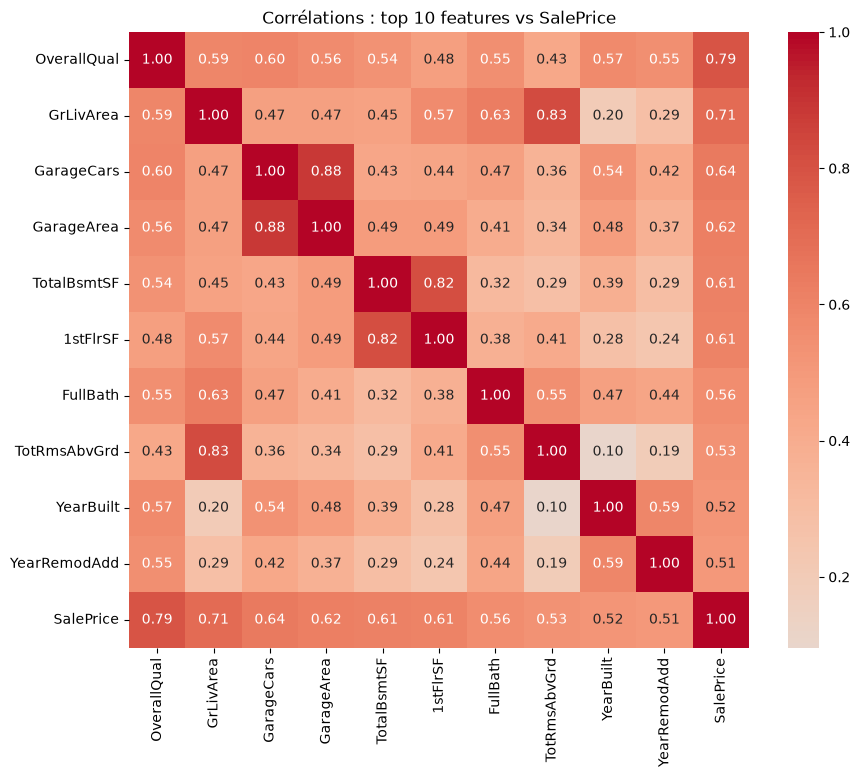

In [12]:
top10 = corr.abs().sort_values(ascending=False).head(10).index.tolist()
plt.figure(figsize=(10, 8))
sns.heatmap(df[top10 + ["SalePrice"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations : top 10 features vs SalePrice")
plt.show()

# scatter plots + boxplot de la qualité

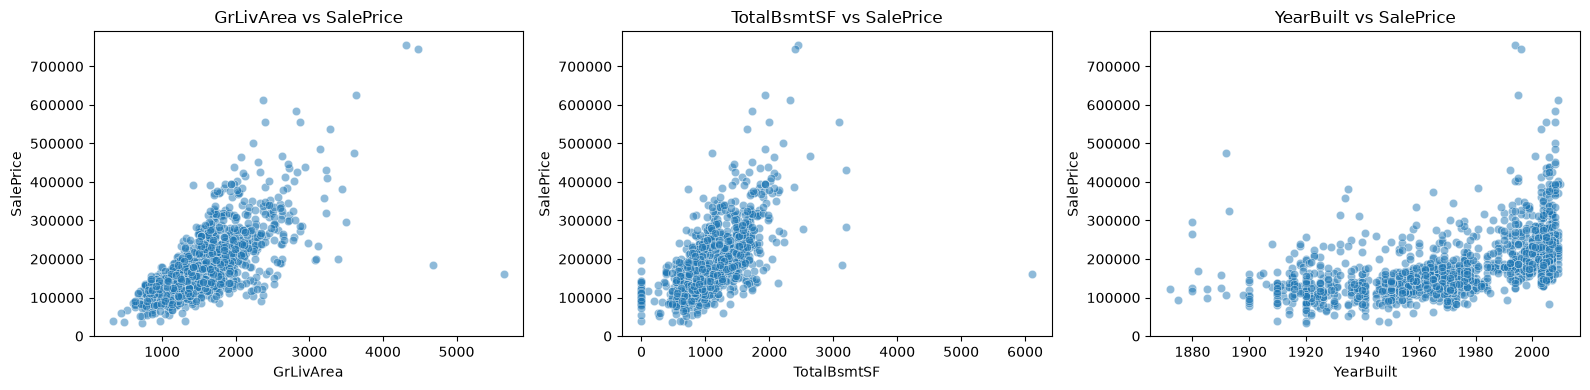

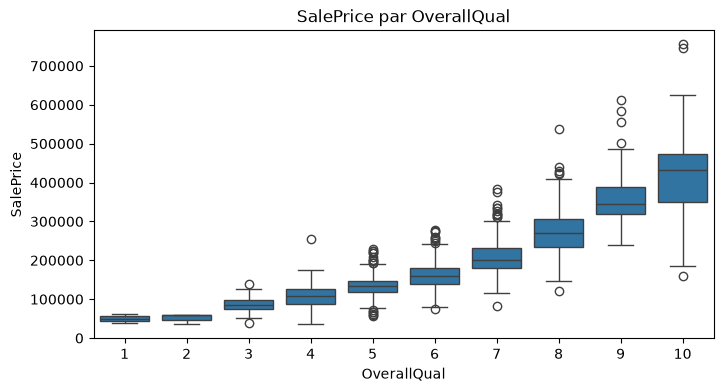

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["GrLivArea", "TotalBsmtSF", "YearBuilt"]):
    sns.scatterplot(x=df[col], y=df["SalePrice"], alpha=0.5, ax=ax)
    ax.set_title(f"{col} vs SalePrice")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["OverallQual"], y=df["SalePrice"])
plt.title("SalePrice par OverallQual")
plt.show()

# catégorielles

Neighborhood    25
Exterior2nd     16
Exterior1st     15
Condition1       9
SaleType         9
HouseStyle       8
RoofMatl         8
Condition2       8
Functional       7
BsmtFinType2     6
dtype: int64


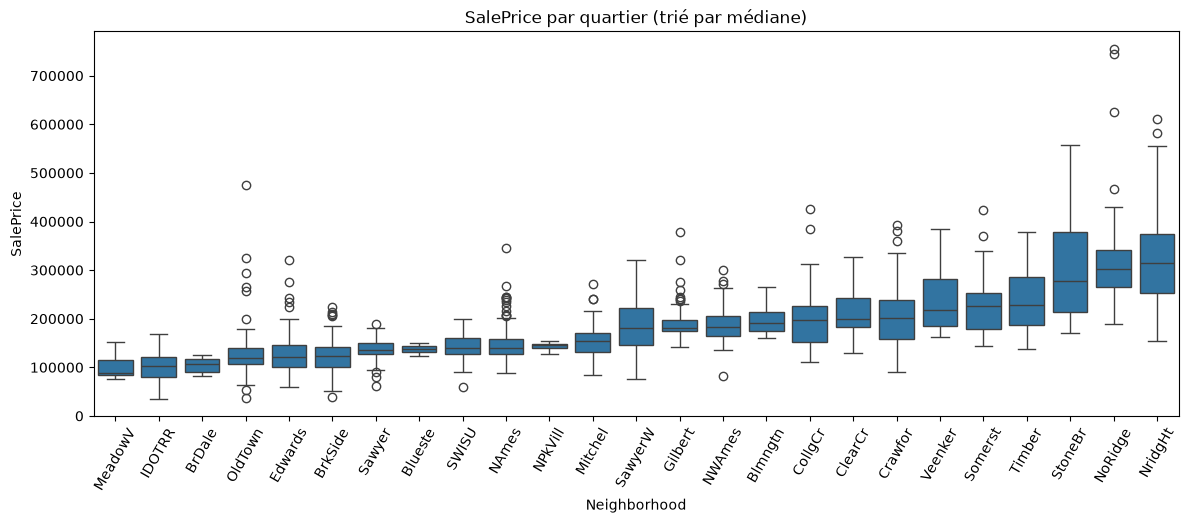

In [15]:
cat_cols = df.select_dtypes(exclude="number").columns
print(df[cat_cols].nunique().sort_values(ascending=False).head(10))

order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14, 5))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order)
plt.xticks(rotation=60)
plt.title("SalePrice par quartier (trié par médiane)")
plt.show()

# enquête MasVnrType

In [16]:
print(df["MasVnrType"].value_counts(dropna=False))

mask = df["MasVnrType"].isna()
print("NaN MasVnrType            :", mask.sum())
print("dont MasVnrArea aussi NaN :", df.loc[mask, "MasVnrArea"].isna().sum())

MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64
NaN MasVnrType            : 872
dont MasVnrArea aussi NaN : 8


## Feature Engineering

In [18]:
d = df_clean = df.drop(columns=["Id", "SalePrice_log"]).copy() # raccourci

d["HouseAge"] = d["YrSold"] - d["YearBuilt"]
d["RemodAge"] = d["YrSold"] - d["YearRemodAdd"]
d["IsRemodeled"] = (d["YearRemodAdd"] != d["YearBuilt"]).astype(int)

d["TotalSF"] = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
d["TotalBath"] = (d["FullBath"] + 0.5 * d["HalfBath"]
                  + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"])
d["TotalPorchSF"] = (d["OpenPorchSF"] + d["EnclosedPorch"] + d["3SsnPorch"]
                     + d["ScreenPorch"] + d["WoodDeckSF"])

d["HasPool"] = (d["PoolArea"] > 0).astype(int)
d["HasGarage"] = (d["GarageArea"] > 0).astype(int)
d["Has2ndFloor"] = (d["2ndFlrSF"] > 0).astype(int)
d["HasFireplace"] = (d["Fireplaces"] > 0).astype(int)

# Vérifications d'incohérences
print("HouseAge < 0 :", (d["HouseAge"] < 0).sum())
print("RemodAge < 0 :", (d["RemodAge"] < 0).sum())
print("GarageYrBlt max :", d["GarageYrBlt"].max())

# Les nouvelles features sont-elles utiles ?
new_feats = ["HouseAge", "RemodAge", "TotalSF", "TotalBath", "TotalPorchSF"]
print(d[new_feats + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice").round(2))

HouseAge < 0 : 0
RemodAge < 0 : 1
GarageYrBlt max : 2010.0
HouseAge       -0.52
RemodAge       -0.51
TotalSF         0.78
TotalBath       0.63
TotalPorchSF    0.39
Name: SalePrice, dtype: float64


In [19]:
nouvelles = ["HouseAge", "RemodAge", "IsRemodeled", "TotalSF", "TotalBath",
             "TotalPorchSF", "HasPool", "HasGarage", "Has2ndFloor", "HasFireplace"]

print("Shape :", df_clean.shape)
df_clean[nouvelles].head()

Shape : (1460, 90)


,HouseAge,RemodAge,IsRemodeled,TotalSF,TotalBath,TotalPorchSF,HasPool,HasGarage,Has2ndFloor,HasFireplace
0,5,5,0,2566,3.5,61,0,1,1,0
1,31,31,0,2524,2.5,298,0,1,0,1
2,7,6,1,2706,3.5,42,0,1,1,1
3,91,36,1,2473,2.0,307,0,1,1,1
4,8,8,0,3343,3.5,276,0,1,1,1


In [20]:
print(df_clean[df_clean["GrLivArea"] > 4000][["GrLivArea", "SalePrice", "SaleCondition"]])

      GrLivArea  SalePrice SaleCondition
523        4676     184750       Partial
691        4316     755000        Normal
1182       4476     745000       Abnorml
1298       5642     160000       Partial


In [21]:
mask_outliers = (df_clean["GrLivArea"] > 4000) & (df_clean["SalePrice"] < 300000)
print("Lignes supprimées :", mask_outliers.sum())
df_clean = df_clean[~mask_outliers].reset_index(drop=True)
print("Shape :", df_clean.shape)

Lignes supprimées : 2
Shape : (1458, 90)


In [22]:
print(df_clean[df_clean["RemodAge"] < 0][["YearBuilt", "YearRemodAdd", "YrSold", "RemodAge"]])

df_clean["RemodAge"] = df_clean["RemodAge"].clip(lower=0)
print("RemodAge < 0 :", (df_clean["RemodAge"] < 0).sum())

Empty DataFrame
Columns: [YearBuilt, YearRemodAdd, YrSold, RemodAge]
Index: []
RemodAge < 0 : 0


## Preprocessing & split

In [25]:
# ---------- Cleaning ----------
df_clean = df.drop(columns=["Id", "SalePrice_log"], errors="ignore").copy()

# NaN = "n'existe pas" -> "None"
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]
for col in none_cols:
    df_clean[col] = df_clean[col].fillna("None")

# Numériques liés à l'absence
df_clean["MasVnrArea"] = df_clean["MasVnrArea"].fillna(0)
df_clean["GarageYrBlt"] = df_clean["GarageYrBlt"].fillna(df_clean["YearBuilt"])

# Code numérique -> catégorie
df_clean["MSSubClass"] = df_clean["MSSubClass"].astype(str)

# 2 outliers (grande surface ET prix bas)
mask_outliers = (df_clean["GrLivArea"] > 4000) & (df_clean["SalePrice"] < 300000)
print("Lignes supprimées :", mask_outliers.sum())
df_clean = df_clean[~mask_outliers].reset_index(drop=True)

# ---------- Feature Engineering ----------
d = df_clean
d["HouseAge"] = d["YrSold"] - d["YearBuilt"]
d["RemodAge"] = (d["YrSold"] - d["YearRemodAdd"]).clip(lower=0)
d["IsRemodeled"] = (d["YearRemodAdd"] != d["YearBuilt"]).astype(int)
d["TotalSF"] = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
d["TotalBath"] = d["FullBath"] + 0.5 * d["HalfBath"] + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"]
d["TotalPorchSF"] = (d["OpenPorchSF"] + d["EnclosedPorch"] + d["3SsnPorch"]
                     + d["ScreenPorch"] + d["WoodDeckSF"])
d["HasPool"] = (d["PoolArea"] > 0).astype(int)
d["HasGarage"] = (d["GarageArea"] > 0).astype(int)
d["Has2ndFloor"] = (d["2ndFlrSF"] > 0).astype(int)
d["HasFireplace"] = (d["Fireplaces"] > 0).astype(int)

# ---------- Contrôles ----------
manquants = df_clean.isnull().sum()
print("NaN restants :\n", manquants[manquants > 0])
print("MSSubClass dtype :", df_clean["MSSubClass"].dtype)
print("Shape :", df_clean.shape)

Lignes supprimées : 2
NaN restants :
 LotFrontage    259
Electrical       1
dtype: int64
MSSubClass dtype : str
Shape : (1458, 90)


In [26]:
# 1. Ordinal encoding (à exécuter UNE seule fois après le cleaning)
qual_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
qual_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
             "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for col in qual_cols:
    df_clean[col] = df_clean[col].map(qual_map)
print("NaN dans les colonnes de qualité :", df_clean[qual_cols].isnull().sum().sum())

# 2. Split
from sklearn.model_selection import train_test_split
X = df_clean.drop(columns="SalePrice")
y = np.log1p(df_clean["SalePrice"])
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.20, random_state=42)
print("Train :", X_train.shape, "| Val :", X_val.shape, "| Test :", X_test.shape)

# 3. Pipeline de preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()
print(len(num_features), "numériques |", len(cat_features), "catégorielles")

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", num_pipe, num_features),
                                  ("cat", cat_pipe, cat_features)])

# 4. Baseline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(model, X_tr, y_tr, X_va, y_va, name):
    model.fit(X_tr, y_tr)
    pred_log = model.predict(X_va)
    rmse_log = np.sqrt(mean_squared_error(y_va, pred_log))
    pred_usd, true_usd = np.expm1(pred_log), np.expm1(y_va)
    mae_usd = mean_absolute_error(true_usd, pred_usd)
    rmse_usd = np.sqrt(mean_squared_error(true_usd, pred_usd))
    r2 = r2_score(y_va, pred_log)
    print(f"{name:20s} | RMSE(log)={rmse_log:.4f} | RMSE($)={rmse_usd:,.0f} | MAE($)={mae_usd:,.0f} | R²={r2:.3f}")

dummy  = Pipeline([("prep", preprocessor), ("model", DummyRegressor(strategy="median"))])
linreg = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
evaluate(dummy,  X_train, y_train, X_val, y_val, "Dummy (médiane)")
evaluate(linreg, X_train, y_train, X_val, y_val, "Linear Regression")

NaN dans les colonnes de qualité : 0
Train : (932, 89) | Val : (234, 89) | Test : (292, 89)
55 numériques | 34 catégorielles
Dummy (médiane)      | RMSE(log)=0.4485 | RMSE($)=97,657 | MAE($)=67,316 | R²=-0.045
Linear Regression    | RMSE(log)=0.1389 | RMSE($)=24,761 | MAE($)=17,039 | R²=0.900


In [27]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

for name, m in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", m)])
    evaluate(pipe, X_train, y_train, X_val, y_val, name)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
for name, m in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", m)])
    scores = -cross_val_score(pipe, X_trainval, y_trainval, cv=kf,
                              scoring="neg_root_mean_squared_error")
    print(f"{name:20s} | CV RMSE(log) = {scores.mean():.4f} ± {scores.std():.4f}")

Linear Regression    | RMSE(log)=0.1389 | RMSE($)=24,761 | MAE($)=17,039 | R²=0.900
Random Forest        | RMSE(log)=0.1572 | RMSE($)=30,377 | MAE($)=20,632 | R²=0.872
Gradient Boosting    | RMSE(log)=0.1436 | RMSE($)=27,016 | MAE($)=18,018 | R²=0.893
Linear Regression    | CV RMSE(log) = 0.1306 ± 0.0119
Random Forest        | CV RMSE(log) = 0.1350 ± 0.0135
Gradient Boosting    | CV RMSE(log) = 0.1219 ± 0.0131
